# Phase 9 — Error analysis

**Purpose.** Eight phases have reported averages. An average of 0.1653 NDCG@10 is compatible
with a model that is mediocre for everyone and with one that is excellent for some users and
useless for the rest — and those call for completely different next steps. This phase asks
*where* the models fail.

Three models are examined, each the best of its family: the **two-tower** (Phase 6), the
**factorization machine** on ids + history (Phase 4), and **item-item cosine** (the Phase 2
floor). Phase 7 cached every model's full score vector for all 5,877 test users, so nothing
here is retrained.

The questions, in order:

1. **Who fails?** How is quality distributed across users, and how many get nothing useful?
2. **Which kinds of user?** Activity, generosity, how mainstream their taste is.
3. **Does taste drift break the models?** Every good model here leans on history. They should
   fail exactly when a user's test-period taste departs from their past.
4. **Which items are missed?** Is failure concentrated in the long tail?
5. **Do the families fail on the same users?** The direct follow-up to Phase 7's finding that
   the tower and FM disagree on 73% of picks yet cannot be combined.
6. **What does a failure actually look like?** Two worked users.

**One protocol note.** Taste drift (question 3) is computed from a user's *test-period*
ratings. That is legitimate for diagnosing errors after the fact and would be leakage if used
to build a model; nothing computed here feeds back into any model.

In [1]:
import sys, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib
from scipy import stats
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")
import data as D, metrics as M

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
COL = {"tower": ACCENT, "fm": WARN, "cosine": MUTED}
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
K = 10
USERS = [int(u) for u in ds.eval_users(True, target="test")]
TRUTH = {u: ds.ground_truth(u) for u in USERS}
SC = {t: joblib.load(f"cache/p7_scores_{t}_s42.joblib")[0] for t in ("tower", "fm", "cosine")}

def topk(tag, u, k=K):
    cand, s = SC[tag][u]
    idx = np.argpartition(-s, k)[:k]
    return cand[idx[np.argsort(-s[idx], kind="stable")]]

TOP = {t: {u: topk(t, u) for u in USERS} for t in SC}

# ---- per-user outcomes ----
rows = []
for u in USERS:
    t = TRUTH[u]; r = {"u": u, "n_truth": len(t)}
    for m in SC:
        lst = TOP[m][u]
        r[f"ndcg_{m}"] = M.ndcg_at_k(lst, t, K)
        r[f"hits_{m}"] = int(sum(int(i) in t for i in lst))
    rows.append(r)
U = pd.DataFrame(rows).set_index("u")

# ---- per-user descriptors (training period only, except drift) ----
tr = ds.split_rows("train"); te = ds.split_rows("test")
logpop = np.log1p(ds.item_train_count)
G = ds.item_genre.toarray()
U["train_n"] = ds.user_train_count[U.index]
U["mean_rating"] = tr.groupby("u")["rating"].mean().reindex(U.index)
U["mainstream"] = tr.groupby("u")["i"].apply(lambda s: logpop[s.to_numpy()].mean()).reindex(U.index)

def genre_dist(df):
    return df.groupby("u")["i"].apply(lambda s: G[s.to_numpy()].sum(0))

eps = 1e-9
gtr = genre_dist(tr[tr.label == 1]); gte = genre_dist(te[te.label == 1])
def jsd(p, q):
    p = p + eps; q = q + eps; p = p / p.sum(); q = q / q.sum(); m = (p + q) / 2
    return 0.5 * (p * np.log2(p / m)).sum() + 0.5 * (q * np.log2(q / m)).sum()
U["drift"] = [jsd(gtr[u], gte[u]) if (u in gtr.index and u in gte.index) else np.nan
              for u in U.index]
U["truth_logpop"] = [logpop[list(TRUTH[u])].mean() for u in U.index]

print(f"\n  {len(U):,} users analysed")
print(U[["ndcg_tower", "ndcg_fm", "ndcg_cosine", "train_n", "mean_rating",
         "mainstream", "drift"]].describe().round(3).to_string())

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg 9cf199d378
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



  5,877 users analysed
       ndcg_tower   ndcg_fm  ndcg_cosine   train_n  mean_rating  mainstream     drift
count    5877.000  5877.000     5877.000  5877.000     5877.000    5877.000  5876.000
mean        0.161     0.113        0.095   117.948        3.742       6.222     0.299
std         0.200     0.164        0.158   136.024        0.420       0.374     0.170
min         0.000     0.000        0.000    10.000        1.086       4.258     0.000
25%         0.000     0.000        0.000    32.000        3.488       5.992     0.173
50%         0.085     0.000        0.000    69.000        3.772       6.244     0.267
75%         0.269     0.182        0.139   148.000        4.037       6.476     0.395
max         1.000     1.000        1.000  1619.000        5.000       7.242     1.000


---
## 1. Who fails?

The medians already say something the averages hid: more than half of users get a top-10 with
no relevant item at all from the FM and from item-item cosine. How concentrated is quality,
and how large is the group every model fails?

In [2]:
print(f"  {'model':<8}{'mean NDCG':>11}{'zero hits':>12}{'>=3 hits':>10}"
      f"{'top 20% users hold':>21}")
print("  " + "-"*62)
for m in SC:
    v = U[f"ndcg_{m}"].sort_values(ascending=False).to_numpy()
    share_top20 = v[: len(v)//5].sum() / v.sum()
    print(f"  {m:<8}{v.mean():>11.4f}{pct((U[f'hits_{m}']==0).mean()):>12}"
          f"{pct((U[f'hits_{m}']>=3).mean()):>10}{pct(share_top20):>21}")

all_fail = (U[["hits_tower", "hits_fm", "hits_cosine"]] == 0).all(axis=1)
print(f"\n  users for whom ALL THREE models return zero relevant items: "
      f"{all_fail.sum():,} ({pct(all_fail.mean())})")
print(f"  mean relevant test items for those users: {U.loc[all_fail, 'n_truth'].mean():.1f}  "
      f"vs {U.loc[~all_fail, 'n_truth'].mean():.1f} for everyone else")

# is zero-hit just "few truth items"? compare against a chance baseline
cand = np.array([len(SC['tower'][u][0]) for u in U.index])
p_chance_hit = 1 - np.exp(-K * U["n_truth"].to_numpy() / cand)   # ~P(>=1 hit) for random top-10
print(f"\n  a RANDOM top-10 would give zero hits to about {pct(1 - p_chance_hit.mean())} of users")

  model     mean NDCG   zero hits  >=3 hits   top 20% users hold
  --------------------------------------------------------------
  tower        0.1613       43.7%     16.2%                61.5%
  fm           0.1130       52.7%     10.4%                68.8%
  cosine       0.0948       60.4%      9.6%                76.8%

  users for whom ALL THREE models return zero relevant items: 1,726 (29.4%)
  mean relevant test items for those users: 6.0  vs 16.3 for everyone else

  a RANDOM top-10 would give zero hits to about 93.5% of users


**Quality is concentrated, and a large group gets nothing.** The top fifth of users hold 61.5%
of the tower's total NDCG, and 1,726 users (29.4%) receive zero relevant items from *all three*
models. For scale, a random top-10 would fail 93.5% of users, so the models are far from
useless — but those universally-failed users have far fewer relevant test items (6.0 vs 16.3),
which makes them harder to hit by arithmetic alone. The next sections have to separate a
genuinely hard user from a user with few targets.

---
## 2. Which kinds of user?

Each descriptor split into quintiles. Every descriptor uses the training period only.

In [3]:
def by_quintile(col, label):
    q = pd.qcut(U[col], 5, duplicates="drop")
    g = U.groupby(q, observed=True)
    out = pd.DataFrame({
        "range": [f"{iv.left:.2f}–{iv.right:.2f}" for iv in g.size().index],
        "tower": g["ndcg_tower"].mean().to_numpy(),
        "fm": g["ndcg_fm"].mean().to_numpy(),
        "cosine": g["ndcg_cosine"].mean().to_numpy(),
        "tower_zero": g["hits_tower"].apply(lambda s: (s == 0).mean()).to_numpy(),
        "n_truth": g["n_truth"].mean().to_numpy(),
    })
    print(f"\n  {label}")
    print(f"  {'quintile':>18}{'tower':>9}{'FM':>9}{'cosine':>9}{'tower zero-hit':>16}{'truth items':>13}")
    for _, r in out.iterrows():
        print(f"  {r['range']:>18}{r['tower']:>9.4f}{r['fm']:>9.4f}{r['cosine']:>9.4f}"
              f"{pct(r['tower_zero']):>16}{r['n_truth']:>13.1f}")
    return out

QA = by_quintile("train_n", "TRAINING ACTIVITY (ratings in train)")
QG = by_quintile("mean_rating", "GENEROSITY (mean training rating)")
QM = by_quintile("mainstream", "MAINSTREAMNESS (mean log-popularity of training items)")

for col in ("train_n", "mean_rating", "mainstream"):
    rho = stats.spearmanr(U[col], U["ndcg_tower"]).statistic
    rho_t = stats.spearmanr(U[col], U["n_truth"]).statistic
    print(f"\n  Spearman with tower NDCG: {col:<12} {rho:+.3f}   (with number of truth items {rho_t:+.3f})")


  TRAINING ACTIVITY (ratings in train)
            quintile    tower       FM   cosine  tower zero-hit  truth items
         10.00–27.00   0.1352   0.0894   0.0652           60.7%          3.0
         27.00–50.00   0.1231   0.0835   0.0653           54.8%          5.4
         50.00–90.00   0.1245   0.0862   0.0731           48.2%          9.1
        90.00–181.00   0.1580   0.1086   0.0908           34.2%         15.8
      181.00–1619.00   0.2661   0.1976   0.1803           20.0%         33.2

  GENEROSITY (mean training rating)
            quintile    tower       FM   cosine  tower zero-hit  truth items
           1.09–3.41   0.1722   0.1240   0.1087           44.3%         12.4
           3.41–3.67   0.1626   0.1151   0.0968           44.5%         12.9
           3.67–3.88   0.1669   0.1159   0.0988           43.1%         14.7
           3.88–4.09   0.1520   0.1034   0.0861           45.0%         13.5
           4.09–5.00   0.1528   0.1066   0.0836           41.3%         12.7

**Generosity does not matter; mainstreamness appears to hurt — but every descriptor is
tangled with how many relevant items a user has.** Activity correlates with the number of
test positives at ρ = +0.846, and the most mainstream quintile has a third as many (6.6 vs
20.5), because heavy users exhaust the popular films and move into the tail. Raw quintile
tables cannot separate these.

---
## 3. Does taste drift break the models?

Drift is measured as the Jensen–Shannon divergence between the genre mix of a user's training
positives and of their test positives. It needs a correction before it means anything: a user
with three test positives *looks* drifted from sampling noise alone. So each user also gets an
**expected** divergence — drawing the same number of items from their own training taste and
measuring how far that sample lands by chance. **Excess drift** is observed minus expected: how
much the user genuinely changed.

A multivariate model then separates the effects, each predictor standardised so coefficients
are comparable.

In [4]:
rng = np.random.default_rng(0)
exp_drift = {}
for u in U.index:
    if u not in gtr.index or u not in gte.index: continue
    items = tr[(tr.u == u) & (tr.label == 1)]["i"].to_numpy()
    n = int(U.at[u, "n_truth"])
    if len(items) == 0 or n == 0: continue
    base = G[items].sum(0)
    draws = [jsd(base, G[rng.choice(items, n, replace=True)].sum(0)) for _ in range(20)]
    exp_drift[u] = float(np.mean(draws))
U["drift_expected"] = pd.Series(exp_drift)
U["drift_excess"] = U["drift"] - U["drift_expected"]

print(f"  observed drift  mean {U['drift'].mean():.3f}")
print(f"  expected drift  mean {U['drift_expected'].mean():.3f}   (from sampling noise alone)")
print(f"  excess drift    mean {U['drift_excess'].mean():+.3f}   sd {U['drift_excess'].std():.3f}")
print(f"  Spearman(observed drift, n_truth) {stats.spearmanr(U['drift'], U['n_truth'], nan_policy='omit').statistic:+.3f}   "
      f"Spearman(excess drift, n_truth) {stats.spearmanr(U['drift_excess'], U['n_truth'], nan_policy='omit').statistic:+.3f}")

q = pd.qcut(U["drift_excess"], 5)
g = U.groupby(q, observed=True)
print(f"\n  {'excess drift quintile':>24}{'tower':>9}{'FM':>9}{'cosine':>9}{'tower zero-hit':>16}{'truth':>8}")
for iv, r in g[["ndcg_tower", "ndcg_fm", "ndcg_cosine", "n_truth"]].mean().iterrows():
    z = (g.get_group(iv)["hits_tower"] == 0).mean()
    print(f"  {f'{iv.left:+.2f} – {iv.right:+.2f}':>24}{r['ndcg_tower']:>9.4f}{r['ndcg_fm']:>9.4f}"
          f"{r['ndcg_cosine']:>9.4f}{pct(z):>16}{r['n_truth']:>8.1f}")

# ---- multivariate: which descriptors matter once the others are held fixed? ----
def ols_hc3(y, Xdf):
    """OLS with HC3 heteroskedasticity-robust standard errors (NDCG is bounded and skewed,
    so constant-variance errors would overstate significance)."""
    X = np.column_stack([np.ones(len(Xdf)), Xdf.to_numpy(float)]); y = np.asarray(y, float)
    XtXi = np.linalg.inv(X.T @ X); b = XtXi @ X.T @ y; e = y - X @ b
    h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    V = XtXi @ (X.T * (e**2 / (1 - h)**2)) @ X @ XtXi
    se = np.sqrt(np.diag(V)); z = b / se
    p = 2 * (1 - stats.norm.cdf(np.abs(z)))
    r2 = 1 - (e**2).sum() / ((y - y.mean())**2).sum()
    return pd.DataFrame({"b": b, "se": se, "p": p}, index=["const"] + list(Xdf.columns)), r2

Z = U.dropna(subset=["drift_excess"]).copy()
Z["log_truth"] = np.log(Z["n_truth"]); Z["log_train"] = np.log(Z["train_n"])
cols = ["log_truth", "log_train", "mean_rating", "mainstream", "drift_excess"]
Xs = (Z[cols] - Z[cols].mean()) / Z[cols].std()
FITS = {m: ols_hc3(Z[f"ndcg_{m}"], Xs) for m in ("tower", "fm", "cosine")}
star = lambda p: "***" if p < .001 else "** " if p < .01 else "*  " if p < .05 else "   "
print(f"\n  OLS on NDCG@10, standardised predictors (coefficient = change per 1 sd), HC3 errors")
print(f"  {'predictor':<14}" + "".join(f"{m:>17}" for m in ("tower", "fm", "cosine")))
for pr in cols:
    print(f"  {pr:<14}" + "".join(f"{FITS[m][0].at[pr,'b']:>+12.4f} {star(FITS[m][0].at[pr,'p'])} "
                                   for m in ("tower", "fm", "cosine")))
print(f"  {'R^2':<14}" + "".join(f"{FITS[m][1]:>17.3f}" for m in ("tower", "fm", "cosine")))

  observed drift  mean 0.299
  expected drift  mean 0.155   (from sampling noise alone)
  excess drift    mean +0.144   sd 0.146
  Spearman(observed drift, n_truth) -0.533   Spearman(excess drift, n_truth) +0.058

     excess drift quintile    tower       FM   cosine  tower zero-hit   truth
             -0.30 – +0.03   0.1918   0.1162   0.0957           38.9%    10.8
             +0.03 – +0.08   0.1774   0.1285   0.1095           37.7%    15.4
             +0.08 – +0.15   0.1674   0.1174   0.1083           39.4%    14.8
             +0.15 – +0.26   0.1508   0.1145   0.0953           44.7%    12.7
             +0.26 – +0.83   0.1192   0.0885   0.0654           57.6%    12.6

  OLS on NDCG@10, standardised predictors (coefficient = change per 1 sd), HC3 errors
  predictor                 tower               fm           cosine
  log_truth          +0.0781 ***      +0.0709 ***      +0.0745 *** 
  log_train          -0.0224 ***      -0.0223 ***      -0.0240 *** 
  mean_rating        -0.019

**Holding the other descriptors fixed changes several stories.** The number of test targets
dominates every model. After it, **taste drift is the tower's largest effect (−0.032 per sd) —
nearly twice its effect on the FM (−0.017) or cosine (−0.020).** The best model is the most
fragile when a user changes, which makes sense for the model that leans hardest on history:
its advantage over the FM is +65% for the most stable fifth of users and +35% for the most
drifted fifth.

Two raw effects reverse or vanish. **Activity flips sign**: at a fixed number of targets,
heavier users are *harder* (−0.022) — plausibly because they have already exhausted the popular
films and their 50-item history window covers a smaller share of their taste. **The apparent
mainstreamness penalty was confounding**: it disappears for the tower and turns slightly
positive for the popularity-leaning FM and cosine. Generous raters are modestly harder once the
rest is held fixed (−0.019): when a user likes most of what they watch, "liked" carries less
information.

These descriptors explain only about 11% of the per-user variance. Most of what separates a
well-served user from a poorly-served one is not captured by any of them.

---
## 4. Which items are missed?

Every (user, relevant test item) pair, grouped by the item's training popularity. For each
decile: its share of all relevant items, and how often each model put it in the top 10.

In [5]:
pairs = [(u, i) for u in U.index for i in TRUTH[u]]
P = pd.DataFrame(pairs, columns=["u", "i"])
P["pop"] = ds.item_train_count[P["i"].to_numpy()]
for m in SC:
    topsets = {u: set(map(int, TOP[m][u])) for u in U.index}
    P[f"hit_{m}"] = [int(i) in topsets[u] for u, i in zip(P["u"], P["i"])]
P["decile"] = pd.qcut(P["pop"].rank(method="first"), 10, labels=range(1, 11))

g = P.groupby("decile", observed=True)
print(f"  {'popularity decile':>18}{'train ratings':>15}{'share of truth':>16}"
      f"{'tower hit':>11}{'FM hit':>9}{'cosine hit':>12}")
for d, r in g.agg(lo=("pop", "min"), hi=("pop", "max"), n=("u", "size"),
                  t=("hit_tower", "mean"), f=("hit_fm", "mean"), c=("hit_cosine", "mean")).iterrows():
    print(f"  {int(d):>18}{f'{r.lo}–{r.hi}':>15}{pct(r.n/len(P)):>16}"
          f"{pct(r.t):>11}{pct(r.f):>9}{pct(r.c):>12}")

print(f"\n  {len(P):,} relevant (user, item) pairs in the filtered test set")
for m in SC:
    top_half = P[P["decile"].astype(int) >= 6][f"hit_{m}"].sum() / max(P[f"hit_{m}"].sum(), 1)
    print(f"  {m:<7} share of its hits coming from the more popular half: {pct(top_half)}")

   popularity decile  train ratings  share of truth  tower hit   FM hit  cosine hit


                   1       0.0–97.0           10.0%       0.6%     0.0%        0.0%
                   2     97.0–169.0           10.0%       1.8%     0.0%        0.0%
                   3    169.0–240.0           10.0%       3.1%     0.2%        0.0%
                   4    240.0–330.0           10.0%       4.5%     0.5%        0.1%
                   5    330.0–432.0           10.0%       6.2%     1.7%        0.1%
                   6    432.0–549.0           10.0%       7.9%     2.5%        0.2%
                   7    549.0–703.0           10.0%       9.5%     4.4%        0.8%
                   8    703.0–893.0           10.0%      13.9%     8.9%        3.6%
                   9   893.0–1256.0           10.0%      17.9%    13.6%        9.6%
                  10  1256.0–3024.0           10.0%      25.9%    35.4%       43.3%

  77,944 relevant (user, item) pairs in the filtered test set
  tower   share of its hits coming from the more popular half: 82.3%
  fm      share of its hits 

**The long tail is where recommendations go missing, and where the tower earns its lead.** Half
of all relevant items sit in the five least popular deciles. The FM retrieves at most 1.7% of
them and item-item cosine essentially none; the tower still reaches 0.6–6.2%. On the most popular
decile the order **reverses** — cosine 43.3%, FM 35.4%, tower 25.9%.

That is the mechanism behind Phase 7. The models are complementary *by popularity*: the FM and
cosine are better at the head, the tower at everything below it. A combiner would need to know
in advance whether a user's next liked film is a blockbuster or a tail item — which is the
ranking problem itself.

One caveat on the bottom decile: part of it is items with fewer than 50 training ratings, which
the candidate filter makes unreachable for every model. The next cell measures how much.

---
## 5. Do the families fail on the same users?

In [6]:
est = set(ds.established.tolist())
P["reachable"] = P["i"].isin(est)
print("  share of each popularity decile the candidate filter makes unreachable:")
print("  " + "  ".join(f"d{int(d)} {pct(1 - v, 0)}" for d, v in P.groupby("decile", observed=True)["reachable"].mean().items()))
pr = P[P.reachable]
print(f"  reachable-only hit rate, bottom half: tower {pct(pr[pr.decile.astype(int)<=5].hit_tower.mean())}, "
      f"FM {pct(pr[pr.decile.astype(int)<=5].hit_fm.mean())}, cosine {pct(pr[pr.decile.astype(int)<=5].hit_cosine.mean())}")

# ---- shared failures ----
zt, zf = U["hits_tower"] == 0, U["hits_fm"] == 0
ct = pd.crosstab(zt.rename("tower fails"), zf.rename("FM fails"))
print(f"\n  zero-hit users (tower rows, FM columns):")
print(ct.to_string())
p_both = (zt & zf).mean(); p_ind = zt.mean() * zf.mean()
print(f"\n  both fail: {pct(p_both)} observed vs {pct(p_ind)} if failures were independent  "
      f"(ratio {p_both/p_ind:.2f})")
print(f"  of users the tower fails, the FM rescues {pct((zt & ~zf).sum()/zt.sum())}; "
      f"of users the FM fails, the tower rescues {pct((zf & ~zt).sum()/zf.sum())}")
rho = stats.spearmanr(U["ndcg_tower"], U["ndcg_fm"]).statistic
print(f"  Spearman of per-user NDCG, tower vs FM: {rho:+.3f}")

# at item level: when both retrieve relevant items, are they the same ones?
both = P[P.hit_tower | P.hit_fm]
print(f"\n  relevant items retrieved by at least one of tower/FM: {len(both):,}")
print(f"    tower only {pct((both.hit_tower & ~both.hit_fm).mean())}   "
      f"FM only {pct((~both.hit_tower & both.hit_fm).mean())}   "
      f"both {pct((both.hit_tower & both.hit_fm).mean())}")
print(f"    median popularity: tower-only {both[both.hit_tower & ~both.hit_fm]['pop'].median():.0f}   "
      f"FM-only {both[~both.hit_tower & both.hit_fm]['pop'].median():.0f}   "
      f"both {both[both.hit_tower & both.hit_fm]['pop'].median():.0f}")

  share of each popularity decile the candidate filter makes unreachable:
  d1 47%  d2 0%  d3 0%  d4 0%  d5 0%  d6 0%  d7 0%  d8 0%  d9 0%  d10 0%
  reachable-only hit rate, bottom half: tower 3.6%, FM 0.5%, cosine 0.0%

  zero-hit users (tower rows, FM columns):
FM fails     False  True 
tower fails              
False         2184   1127
True           597   1969

  both fail: 33.5% observed vs 23.0% if failures were independent  (ratio 1.46)
  of users the tower fails, the FM rescues 23.3%; of users the FM fails, the tower rescues 36.4%
  Spearman of per-user NDCG, tower vs FM: +0.506

  relevant items retrieved by at least one of tower/FM: 9,792
    tower only 46.4%   FM only 27.4%   both 26.2%
    median popularity: tower-only 703   FM-only 1305   both 1290


**The gap is real, and the failures are structured.** Only the bottom popularity decile is
affected by the candidate filter; on reachable items alone the bottom half still goes tower
3.6%, FM 0.5%, cosine 0.0%.

The tower and FM fail the same users 1.46× more often than chance — there is a shared hard core
of 1,969 users (33.5%) — but they are far from redundant: the FM rescues 23.3% of the tower's
failures and the tower rescues 36.4% of the FM's. Among relevant items either model retrieves,
46.4% are found only by the tower, at a median popularity of 703 training ratings, and 27.4%
only by the FM, at a median of 1,305. **The FM's unique successes are head items; the tower's are
not.**

---
## 6. What does failure look like?

Two users with a similar number of relevant test items: one the tower serves very well, and one
that all three models fail while their taste drifts sharply.

In [7]:
GN = D.GENRES
def genre_mix(items, top=4):
    v = G[np.asarray(list(items), int)].sum(0)
    idx = np.argsort(-v)[:top]
    return ", ".join(f"{GN[j]} {v[j]/v.sum():.0%}" for j in idx if v[j] > 0)

def show(u, title):
    trpos = tr[(tr.u == u) & (tr.label == 1)]["i"].to_numpy()
    print(f"  --- {title}: user {u} ---")
    print(f"  training history: {int(U.at[u,'train_n'])} ratings, mean {U.at[u,'mean_rating']:.2f}; "
          f"excess drift {U.at[u,'drift_excess']:+.2f}")
    print(f"  liked in training   {genre_mix(trpos)}")
    print(f"  liked in test       {genre_mix(TRUTH[u])}   ({len(TRUTH[u])} items)")
    for m in ("tower", "fm"):
        lst = TOP[m][u]
        mark = lambda i: "*" if int(i) in TRUTH[u] else " "
        print(f"  {m:<6} NDCG {U.at[u, f'ndcg_{m}']:.3f}  recommended:")
        for i in lst[:6]:
            print(f"       {mark(i)} {ds.item_title[i][:44]:<46}{ds.item_train_count[i]:>5} ratings")
    print()

band = U[(U.n_truth >= 8) & (U.n_truth <= 14)]
good = band.sort_values(["ndcg_tower", "drift_excess"], ascending=[False, True]).index[0]
bad_pool = band[(band.hits_tower == 0) & (band.hits_fm == 0) & (band.hits_cosine == 0)]
bad = bad_pool.sort_values("drift_excess", ascending=False).index[0]
show(good, "served well"); show(bad, "failed by every model")
print("  * = a film the user actually liked in the test period")

  --- served well: user 5395 ---
  training history: 58 ratings, mean 4.03; excess drift +0.11
  liked in training   Action 16%, Sci-Fi 12%, Comedy 9%, Adventure 8%
  liked in test       Sci-Fi 32%, Action 22%, Adventure 15%, Horror 10%   (13 items)
  tower  NDCG 0.821  recommended:
       * Total Recall (1990)                            1623 ratings
       * Jurassic Park (1993)                           2231 ratings
         Tron (1982)                                     705 ratings
       * Heavy Metal (1981)                              456 ratings
       * Army of Darkness (1993)                         810 ratings
       * Superman (1978)                                 874 ratings
  fm     NDCG 0.302  recommended:
         Star Trek: The Wrath of Khan (1982)            1160 ratings
       * Total Recall (1990)                            1623 ratings
         Star Trek IV: The Voyage Home (1986)            882 ratings
         Batman (1989)                                  1042 

**The two cases show both mechanisms at once.** User 5395's taste barely moved, and the tower
put five films they went on to like into its first six picks, several of them mid-popularity.
User 5821 went from a training history that was 40% Horror to test-period likes that were 83%
Drama. Every model failed them, but differently: the tower stayed faithful to their past and
recommended horror classics, while the FM fell back on blockbusters. Neither failure is a bug.
A history-based model has no signal that a user is about to change.

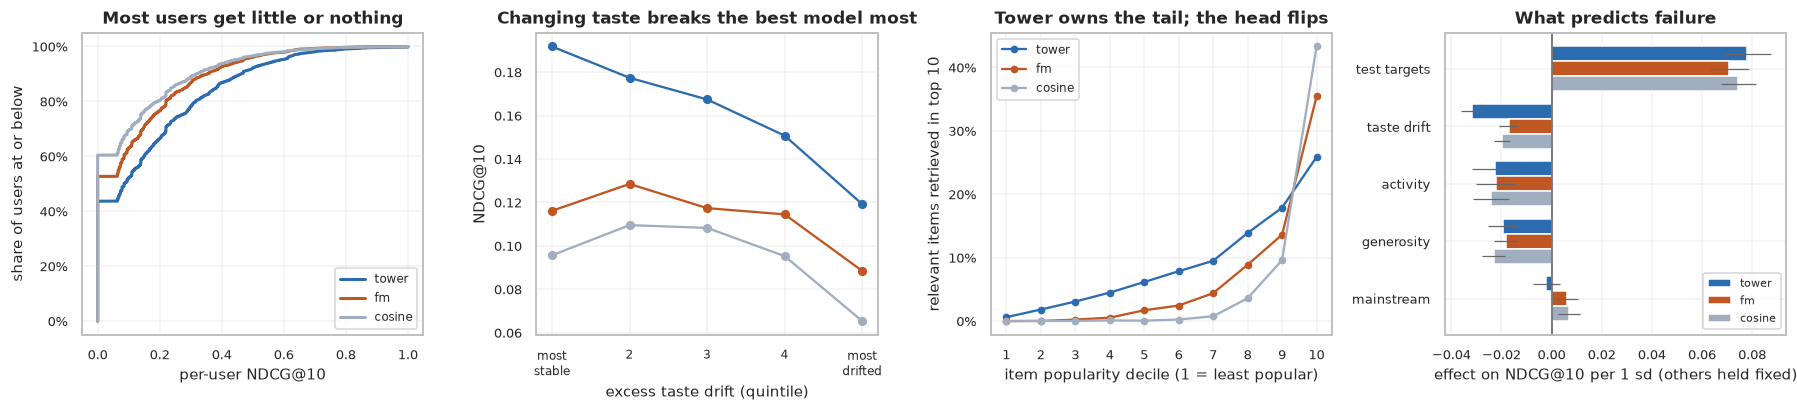

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16.5, 3.9))

ax = axes[0]
for m in ("tower", "fm", "cosine"):
    v = np.sort(U[f"ndcg_{m}"].to_numpy())
    ax.plot(v, np.arange(1, len(v)+1)/len(v), color=COL[m], lw=2, label=m)
ax.set_xlabel("per-user NDCG@10"); ax.set_ylabel("share of users at or below")
ax.set_title("Most users get little or nothing")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
qd = pd.qcut(U["drift_excess"], 5)
gd = U.groupby(qd, observed=True)[["ndcg_tower", "ndcg_fm", "ndcg_cosine"]].mean()
x = np.arange(1, 6)
for m in ("tower", "fm", "cosine"):
    ax.plot(x, gd[f"ndcg_{m}"].to_numpy(), "-o", ms=5, color=COL[m], label=m)
ax.set_xticks(x); ax.set_xticklabels(["most\nstable", "2", "3", "4", "most\ndrifted"], fontsize=8)
ax.set_ylabel("NDCG@10"); ax.set_xlabel("excess taste drift (quintile)")
ax.set_title("Changing taste breaks the best model most")

ax = axes[2]
hr = P.groupby("decile", observed=True)[["hit_tower", "hit_fm", "hit_cosine"]].mean()
xd = np.arange(1, 11)
for m in ("tower", "fm", "cosine"):
    ax.plot(xd, hr[f"hit_{m}"].to_numpy(), "-o", ms=4, color=COL[m], label=m)
ax.set_xticks(xd); ax.set_xlabel("item popularity decile (1 = least popular)")
ax.set_ylabel("relevant items retrieved in top 10")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Tower owns the tail; the head flips")
ax.legend(fontsize=8, loc="upper left")

ax = axes[3]
preds = ["log_truth", "drift_excess", "log_train", "mean_rating", "mainstream"]
labels = ["test targets", "taste drift", "activity", "generosity", "mainstream"]
y = np.arange(len(preds)); w = 0.26
for j, m in enumerate(("tower", "fm", "cosine")):
    b = [FITS[m][0].at[p, "b"] for p in preds]
    e = [1.96 * FITS[m][0].at[p, "se"] for p in preds]
    ax.barh(y + (j-1)*w, b, w, xerr=e, color=COL[m], edgecolor="white",
            error_kw=dict(ecolor="0.4", lw=0.8), label=m)
ax.axvline(0, color="0.35", lw=1)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8.5); ax.invert_yaxis()
ax.set_xlabel("effect on NDCG@10 per 1 sd (others held fixed)")
ax.set_title("What predicts failure")
ax.legend(fontsize=7.5, loc="lower right")

plt.tight_layout(); plt.show()
U.reset_index().to_csv("results_phase9_users.csv", index=False)

---
## 7. Findings

### Averages hide a population that gets nothing

| | mean NDCG@10 | users with zero hits | NDCG held by top 20% of users |
|---|---|---|---|
| two-tower | 0.1613 | 43.7% | 61.5% |
| FM | 0.1130 | 52.7% | 68.8% |
| item-item cosine | 0.0948 | 60.4% | 76.8% |

**29.4% of users — 1,726 people — receive no relevant item from any of the three models.** A
random top-10 would fail 93.5%, so the models work; but quality is concentrated in a minority,
and the better the model, the less concentrated it is.

### What predicts failure, once the confounds are removed

Every raw descriptor is tangled with how many relevant test items a user has, so the effects are
read from a multivariate model with standardised predictors:

| Predictor (per 1 sd) | tower | FM | cosine |
|---|---|---|---|
| number of test targets | +0.078 | +0.071 | +0.075 |
| **excess taste drift** | **−0.032** | −0.017 | −0.020 |
| training activity | −0.022 | −0.022 | −0.024 |
| rating generosity | −0.019 | −0.018 | −0.023 |
| mainstream taste | n.s. | +0.006 | +0.007 |

- **Taste drift is the tower's largest effect after target count, nearly twice its effect on the
  other models.** The model that uses history best is the one most exposed when history stops
  describing the user. Its NDCG falls 38% from the most stable fifth of users to the most drifted,
  and its lead over the FM shrinks from +65% to +35%.
- **Drift had to be corrected before it meant anything.** Raw genre divergence correlates with
  test-set size at ρ = −0.533, because a handful of test items looks "drifted" by sampling noise.
  Subtracting each user's expected divergence under no change reduces that to +0.058.
- **Activity reverses sign.** Its raw positive association was entirely via having more targets;
  at a fixed number of targets heavier users are *harder*, plausibly because they have exhausted
  the popular films and a 50-item history window covers less of their taste.
- **The apparent penalty for mainstream taste was confounding**, and it vanishes for the tower.
- These descriptors explain only ~11% of per-user variance. Most of what separates a well-served
  user from a poorly-served one is not captured by any of them.

### The long tail is where recommendations go missing — and where the tower wins

Half of all relevant items sit in the five least popular deciles. On reachable items the tower
retrieves **3.6%** of them, the FM **0.5%**, item-item cosine **0.0%**. On the most popular decile
the order **reverses**: cosine 43.3%, FM 35.4%, tower 25.9%. 82.3% of the tower's hits come from
the more popular half of the catalogue; for the FM it is 96.3%, for cosine 99.6%.

### This explains Phase 7

The tower and FM fail the same users 1.46× more often than chance, so a shared hard core exists.
But their *successes* are split by popularity: items only the tower finds have a median of 703
training ratings, items only the FM finds a median of 1,305. The models are complementary along
an axis a combiner cannot see in advance — whether a given user's next liked film is a
blockbuster or a tail item — which is why a 98% oracle headroom produced no usable gain.

### What would help, following directly from this

Stated as untested directions, not results:

- **Drift-aware history.** Recency-weighting the history window, or session-level signals, targets
  the tower's largest failure mode directly.
- **A popularity-conditioned combination.** A global blend failed in Phase 7; weighting the FM
  toward head items and the tower toward the tail is a different mechanism aimed at exactly the
  split measured here.
- **Tail exposure as a first-class objective.** Every model loses the bottom half of the catalogue;
  a metric that rewards reaching it would change which model looks best.